# Notebook 03 — Análisis exploratorio (EDA)

**Qué hace este notebook:** explora el dataset ya limpio (`lineas_limpias.parquet`, notebook 02) para responder P1 y P2, descubrir patrones que alimenten las hipótesis y construir la segmentación de clientes (RFM). Se divide en tres bloques: **univariado → multivariado → clientes (RFM y cohortes)**.

**Regla de lectura:** cada gráfico termina con una conclusión de una o dos frases; si un gráfico no dice algo, no se queda.

In [1]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Rutas del proyecto (los notebooks viven en /notebooks)
RAIZ = Path('..').resolve()
RAW = RAIZ / 'data' / 'raw' / 'online_retail_II.csv'
PROC = RAIZ / 'data' / 'processed'
FIG = RAIZ / 'docs' / 'figuras'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

In [2]:
df = pd.read_parquet(PROC / 'lineas_limpias.parquet')
ventas = df[df['tipo'] == 'Venta'].copy()
print(f'{len(df):,} lineas | {len(ventas):,} de venta | {df.loc[df["tipo"]=="Devolucion"].shape[0]:,} de devolucion')

# Pedidos (una fila por factura de venta)
pedidos = (ventas.groupby('factura')
           .agg(fecha=('fecha_hora', 'min'), cliente_id=('cliente_id', 'first'), pais=('pais', 'first'),
                pais_grupo=('pais_grupo', 'first'), lineas=('codigo', 'size'),
                productos=('codigo', 'nunique'), unidades=('cantidad', 'sum'),
                importe=('importe', 'sum'))
           .reset_index())
pedidos['precio_medio'] = pedidos['importe'] / pedidos['unidades']
print(f'{len(pedidos):,} pedidos de venta')

1,021,326 lineas | 1,003,413 de venta | 17,913 de devolucion


39,514 pedidos de venta


## 1. Variables numéricas

Las tres variables base (`cantidad`, `precio`, `importe`) son muy asimétricas por el carácter mayorista. Se mide la asimetría (*skew*) y la curtosis para decidir cómo graficarlas y qué pruebas estadísticas usar más adelante.

In [3]:
num = ventas[['cantidad', 'precio', 'importe']]
resumen = num.describe(percentiles=[.25, .5, .75, .95, .99]).T
resumen['skew'] = num.skew()
resumen['curtosis'] = num.kurt()
resumen[['count', 'mean', 'std', 'min', '25%', '50%', '75%', '95%', '99%', 'max', 'skew', 'curtosis']]

,count,mean,std,min,25%,50%,75%,95%,99%,max,skew,curtosis
cantidad,"1,003,413.00",11.00,67.45,1.00,1.00,4.00,12.00,32.00,108.00,"19,152.00",99.16,"16,655.69"
precio,"1,003,413.00",3.34,4.76,0.03,1.25,2.10,4.13,9.95,16.95,"1,157.15",41.00,"5,971.98"
importe,"1,003,413.00",19.33,76.01,0.06,4.13,10.08,17.70,59.50,179.00,"38,970.00",160.90,"71,484.51"


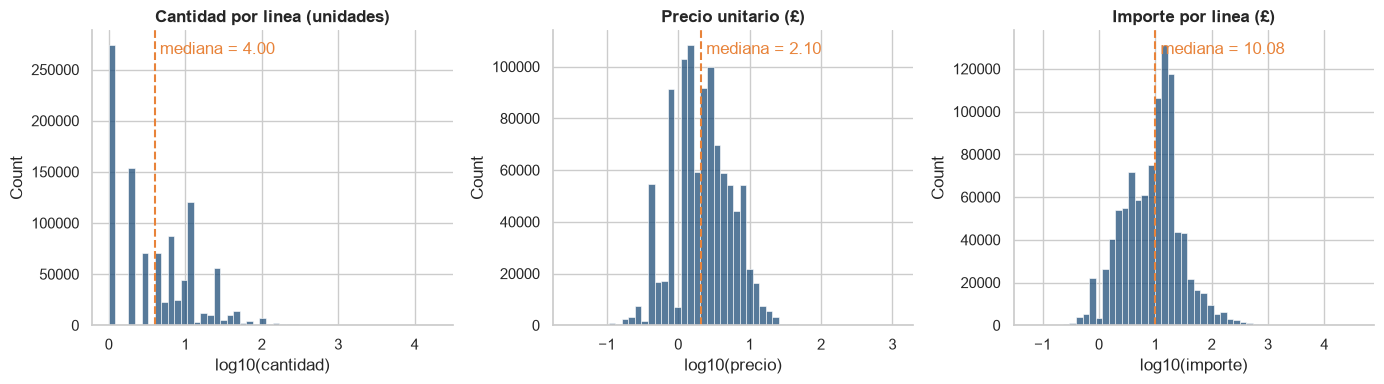

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, tit in zip(axs, ['cantidad', 'precio', 'importe'],
                        ['Cantidad por linea (unidades)', 'Precio unitario (£)', 'Importe por linea (£)']):
    sns.histplot(np.log10(ventas[col]), bins=50, color=AZUL, ax=ax)
    ax.set_xlabel(f'log10({col})'); ax.set_title(tit)
    mediana = np.log10(ventas[col].median())
    ax.axvline(mediana, color=NARANJA, ls='--')
    ax.text(mediana, ax.get_ylim()[1] * .92, f' mediana = {ventas[col].median():,.2f}', color=NARANJA)
plt.tight_layout()
plt.savefig(FIG / '03_distribuciones_numericas.png', dpi=150, bbox_inches='tight')
plt.show()

**Qué muestran las tres distribuciones:**
- Las tres variables tienen **colas larguísimas** (asimetría de 41 a 161): la mediana de una línea es de **4 unidades, £2,10 de precio y £10 de importe**, pero el máximo llega a 19.152 unidades y £38.970.
- Por eso en el resto del proyecto se reportan **medianas** además de promedios y se usan **escalas logarítmicas**: el promedio (£19 por línea) es casi el doble de la mediana (£10).
- En escala log `precio` e `importe` se ven casi simétricos, lo que justifica trabajar con el logaritmo en las pruebas de hipótesis. `cantidad` sigue concentrada en valores bajos (muchas líneas de 1 a 3 unidades, porque son enteros), pero con una cola mucho más corta que en escala normal.

## 2. A nivel de pedido

Un pedido es la unidad con la que el negocio piensa (ticket, devoluciones, recompra). Se resumen sus tres magnitudes: líneas por pedido, unidades y valor.

In [5]:
pedidos[['lineas', 'productos', 'unidades', 'importe']].describe(percentiles=[.5, .9, .99]).T

,count,mean,std,min,50%,90%,99%,max
lineas,"39,514.00",25.39,42.62,1.00,15.00,52.00,198.00,"1,113.00"
productos,"39,514.00",25.11,42.28,1.00,15.00,51.00,196.87,"1,109.00"
unidades,"39,514.00",279.22,"1,070.74",1.00,148.00,523.00,"2,223.61","87,167.00"
importe,"39,514.00",490.96,"1,126.90",0.19,301.21,905.49,"4,097.99","52,940.94"


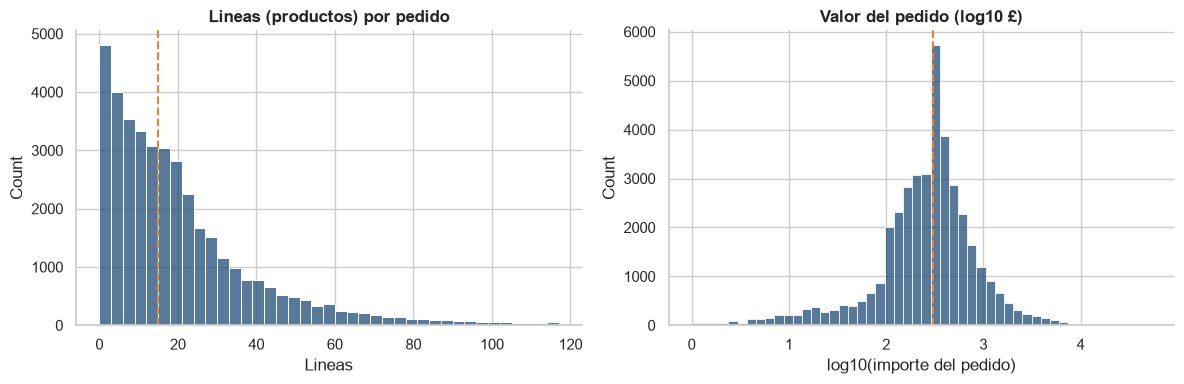

Pedido mediano: 15 lineas y £301  |  pedido promedio: £491


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(pedidos['lineas'], bins=range(0, 120, 3), color=AZUL, ax=axs[0])
axs[0].set_title('Lineas (productos) por pedido'); axs[0].set_xlabel('Lineas')
sns.histplot(np.log10(pedidos['importe'].clip(lower=1)), bins=50, color=AZUL, ax=axs[1])
axs[1].set_title('Valor del pedido (log10 £)'); axs[1].set_xlabel('log10(importe del pedido)')
for ax, v in zip(axs, [pedidos['lineas'].median(), np.log10(pedidos['importe'].median())]):
    ax.axvline(v, color=NARANJA, ls='--')
plt.tight_layout()
plt.show()
print(f'Pedido mediano: {pedidos["lineas"].median():.0f} lineas y £{pedidos["importe"].median():,.0f}  |  pedido promedio: £{pedidos["importe"].mean():,.0f}')

**El pedido típico** tiene 15 líneas y vale **£301** (mediana). El promedio es **£491**: unos pocos pedidos grandes (el 1 % más grande pasa de £4.098) jalan el promedio hacia arriba. Esto confirma que en este negocio **el promedio engaña**: para hablar de un pedido "típico" hay que usar la mediana.

## 3. Variables categóricas: países y productos

Reino Unido concentra 85.3% de las ventas brutas


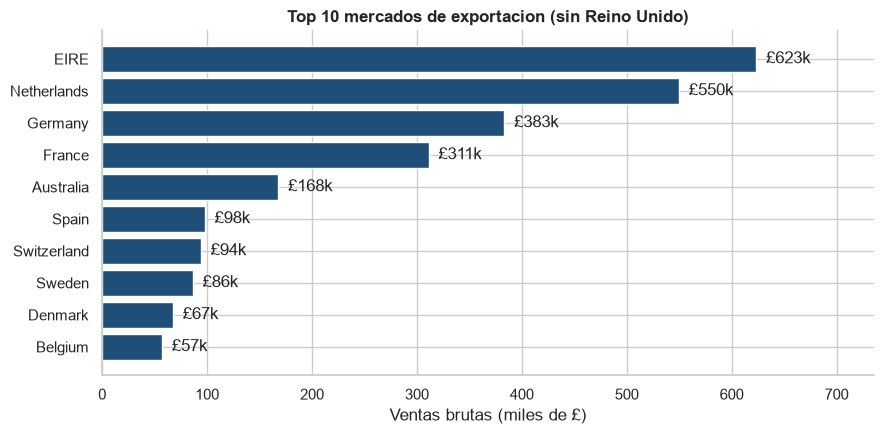

In [7]:
por_pais = (ventas.groupby('pais')['importe'].sum().sort_values(ascending=False))
uk_share = por_pais['United Kingdom'] / por_pais.sum()
print(f'Reino Unido concentra {uk_share:.1%} de las ventas brutas')

fig, ax = plt.subplots(figsize=(9, 4.5))
top = por_pais.drop('United Kingdom').head(10)[::-1]
ax.barh(top.index, top.values / 1000, color=AZUL)
for i, v in enumerate(top.values / 1000):
    ax.text(v, i, f'  £{v:,.0f}k', va='center')
ax.set_title('Top 10 mercados de exportacion (sin Reino Unido)')
ax.set_xlabel('Ventas brutas (miles de £)')
ax.set_xlim(0, top.max() / 1000 * 1.18)
plt.tight_layout()
plt.savefig(FIG / '03_top_paises_exterior.png', dpi=150, bbox_inches='tight')
plt.show()

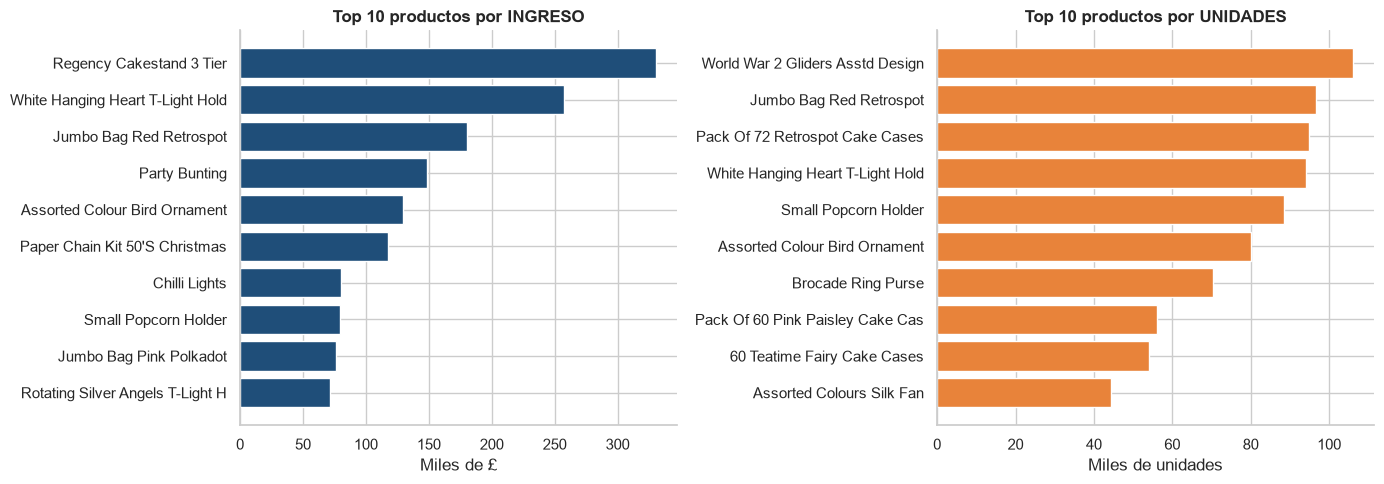

Productos en comun entre ambos rankings: 4


In [8]:
prod = ventas.groupby(['codigo', 'descripcion']).agg(ingreso=('importe', 'sum'), unidades=('cantidad', 'sum')).reset_index()

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
t1 = prod.nlargest(10, 'ingreso')[::-1]
axs[0].barh(t1['descripcion'].str.title().str[:32], t1['ingreso'] / 1000, color=AZUL)
axs[0].set_title('Top 10 productos por INGRESO'); axs[0].set_xlabel('Miles de £')
t2 = prod.nlargest(10, 'unidades')[::-1]
axs[1].barh(t2['descripcion'].str.title().str[:32], t2['unidades'] / 1000, color=NARANJA)
axs[1].set_title('Top 10 productos por UNIDADES'); axs[1].set_xlabel('Miles de unidades')
plt.tight_layout()
plt.savefig(FIG / '03_top_productos.png', dpi=150, bbox_inches='tight')
plt.show()
print('Productos en comun entre ambos rankings:', len(set(t1['codigo']) & set(t2['codigo'])))

**Países.** El **Reino Unido concentra el 85 % de las ventas**; el resto del mundo es un mercado pequeño pero diverso. Entre los mercados de exportación lideran EIRE, Países Bajos, Alemania y Francia.

**Productos.** El producto que más ingresos deja (Regency Cakestand 3 Tier) **no es el que más unidades vende** (World War 2 Gliders, que cuesta muy poco). Solo **4 de los 10 productos coinciden** entre ambos rankings: ordenar el catálogo por unidades o por ingresos lleva a decisiones de inventario diferentes, y conviene mirar ambos.

## 4. Patrones temporales (P1)

Se excluye **diciembre de 2011** porque los datos terminan el día 9 (compararlo con un diciembre completo sería engañoso).

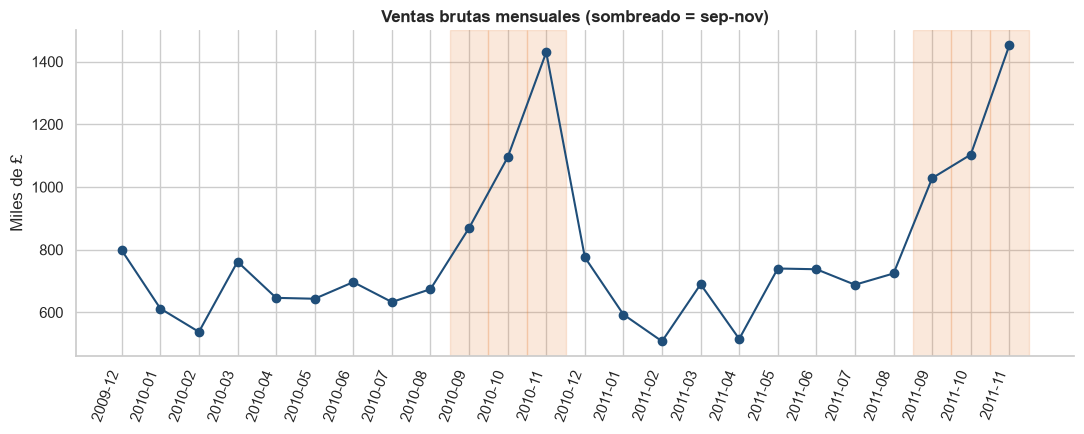

In [9]:
completo = ventas[~ventas['mes_incompleto']]
mensual = completo.groupby('anio_mes')['importe'].sum()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(mensual.index, mensual.values / 1000, marker='o', color=AZUL)
for i, m in enumerate(mensual.index):
    if int(m[5:]) in (9, 10, 11):
        ax.axvspan(i - .5, i + .5, color=NARANJA, alpha=.18)
ax.set_xticks(range(len(mensual)))
ax.set_xticklabels(mensual.index, rotation=70, ha='right')
ax.set_title('Ventas brutas mensuales (sombreado = sep-nov)')
ax.set_ylabel('Miles de £')
plt.tight_layout()
plt.savefig(FIG / '03_ventas_mensuales.png', dpi=150, bbox_inches='tight')
plt.show()

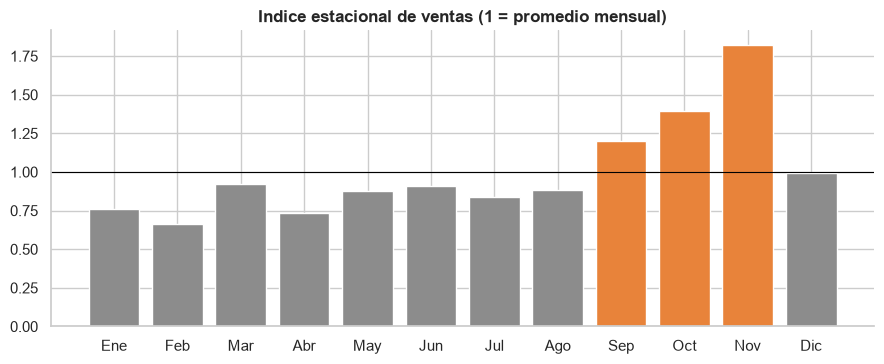

mes,1,2,3,4,5,6,7,8,9,10,11,12
indice,0.76,0.66,0.92,0.74,0.88,0.91,0.84,0.89,1.20,1.39,1.82,1.00


In [10]:
# Indice estacional: promedio del mes calendario / promedio mensual global (solo meses completos)
mensual_df = mensual.reset_index()
mensual_df['mes'] = mensual_df['anio_mes'].str[5:].astype(int)
indice = mensual_df.groupby('mes')['importe'].mean() / mensual_df['importe'].mean()

fig, ax = plt.subplots(figsize=(9, 3.8))
colores = [NARANJA if v > 1.15 else GRIS for v in indice.values]
ax.bar(indice.index, indice.values, color=colores)
ax.axhline(1, color='black', lw=.8)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic'])
ax.set_title('Indice estacional de ventas (1 = promedio mensual)')
plt.tight_layout()
plt.savefig(FIG / '03_indice_estacional.png', dpi=150, bbox_inches='tight')
plt.show()
indice.round(2).to_frame('indice').T

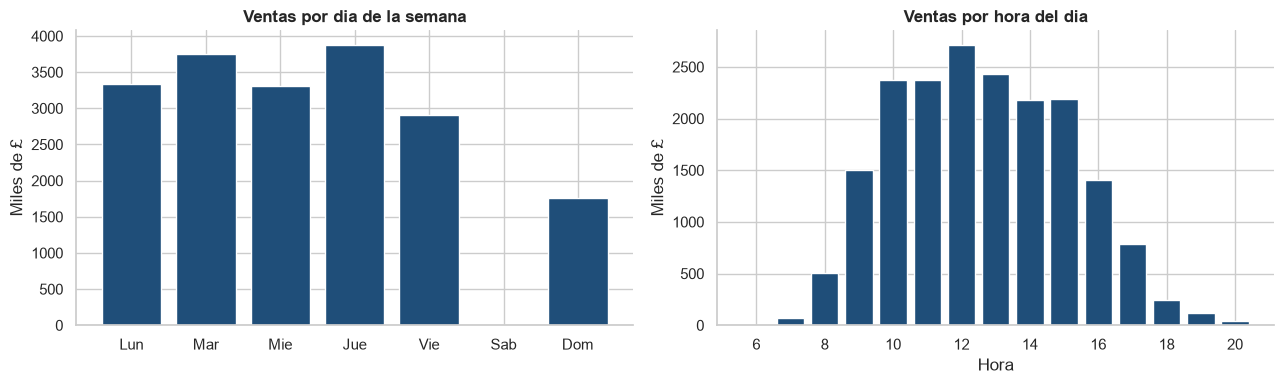

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
dias = ['Lun', 'Mar', 'Mie', 'Jue', 'Vie', 'Sab', 'Dom']
por_dia = completo.groupby('dia_semana')['importe'].sum().reindex(range(7), fill_value=0)
axs[0].bar([dias[i] for i in por_dia.index], por_dia.values / 1000, color=AZUL)
axs[0].set_title('Ventas por dia de la semana'); axs[0].set_ylabel('Miles de £')
por_hora = completo.groupby('hora')['importe'].sum()
axs[1].bar(por_hora.index, por_hora.values / 1000, color=AZUL)
axs[1].set_title('Ventas por hora del dia'); axs[1].set_xlabel('Hora'); axs[1].set_ylabel('Miles de £')
plt.tight_layout()
plt.show()

**Estacionalidad (P1).**
- Las ventas mensuales tienen un patrón claro y repetido en 2010 y 2011: **suben desde septiembre y alcanzan su máximo en noviembre**, y caen en enero–febrero.
- El índice estacional lo cuantifica: septiembre = **1,20**, octubre = **1,39**, noviembre = **1,82** veces el mes promedio, frente a 0,66–0,92 en el resto de meses. De aquí sale la definición de **temporada alta = septiembre–noviembre** que usan la hipótesis H1 y el dashboard.
- **Día y hora:** el **jueves** es el día más fuerte (20,5 % de las ventas); el viernes es el más flojo entre semana; el **sábado prácticamente no hay ventas** (0,05 %) y el domingo sí (~9 %). Cerca del **75 % de las ventas ocurre entre las 10:00 y las 15:59**, con pico a las 12:00. Es el patrón de un cliente que compra en horario de oficina: negocios que reponen inventario.